# Task 1: Importing the required libraries

Performing data analysis and building a machine learning model requires several python libraries to be imported.

- **Pandas** is used for loading and manipulating datasets.
- **Numpy** is used for numerical computations.
- **Matplotlib** and **Seaborn** are used for data visualisations.
- **Scikit-Learn** provides machine learning tools including data splitting,model training and evaluation.

These libraries form the foundation of data analysis and predictive modelling in Python.  


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Display settings
%matplotlib inline

# Task 2: Loading and exploring the dataset

The Medical Insurance dataset obtained from keggle contains information about individuals as well as the medical insurance charges associated with them.

## Description of variables

- **age**: Age of the client.
- **sex**: Gender of the client.
- **bmi**: Body Mass Index, an indicator of body fat based on weight and height.
- **children**: Number of dependents covered by the insurance.
- **smoker**: Indicates whether the client is a smoker or not.
- **region**: Residential region of the client.
- **charges**: This is the target variable, it is the medical insurance costs charged to the client.

The purpose of the analysis is to analyse the medical insurance dataset, examine the above variables and understand the factors affecting insurance charges and to build and evaluate a linear regression predictive model.
 

In [4]:
# loading the dataset
df = pd.read_csv("C:\\Users\\charl\\Downloads\\insurance.csv.csv")

# Displaying the first five rows
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (1338, 7)


In [6]:
# Information about dataset structure
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [7]:
# Summary statistics
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
# Missing values
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [13]:
# Checking for duplicated rows
print("Exact duplicated rows:", df.duplicated().sum())

Exact duplicated rows: 1


In [25]:
# Removing duplicated rows and verification after removal
df = df.drop_duplicates()
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (1337, 7)


## Dataset exploration findings

## Number of records
The dataset originally contained 1338 records(rows) and 7 variables(columns). During the data quality assessment, there was one duplicate record that was identified and removed and the final dataset that was used for analysis therefore contained 1337 records and 7 variables.

## Types of data
The dataset inlcudes both numerical and categorical variables
- Numerical: age, bmi, children, charges
- Categorical: sex, smoker, region

## Missing values
There are no missing values.

## Summary statistics
The summary statistics provide insights into the distribution of numerical variables.

# Task 3: Exploratory Data Analysis
EDA, in this task, is used to determine whether the data is sufficiently clean and can be used to develop the linear regression model. It helps us understand patterns, relationships, and trends within the dataset. The goal here is to identify which variables may influence medical insurance charges and how strongly they affect costs.

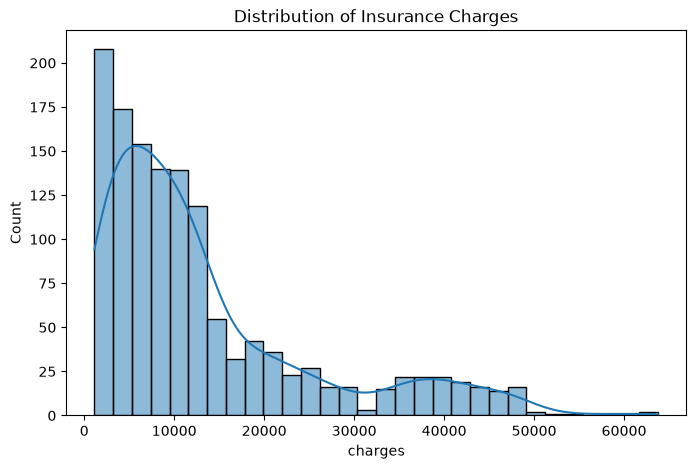

Charges skewness: 1.515
Charges median: 9386.16
Charges mean: 13279.12


In [16]:
# Distribution of charges
plt.figure(figsize=(8,5))
sns.histplot(df['charges'], kde=True)
plt.title("Distribution of Insurance Charges")
plt.xlabel("charges")
plt.show()

print("Charges skewness:", round(df_clean["charges"].skew(), 3))
print("Charges median:", round(df_clean["charges"].median(), 2))
print("Charges mean:", round(df_clean["charges"].mean(), 2))
             

### Interpretation
While most individuals have moderate medical costs, a smaller group incurs very high expenses. This is demonstrated by insurance charges being positively skewed.

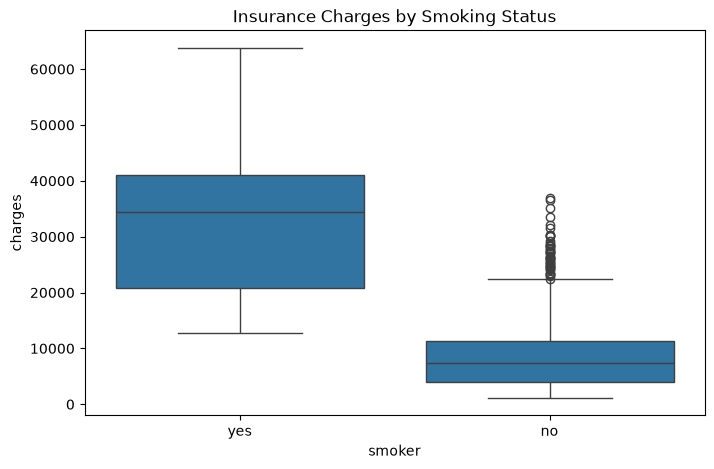

In [17]:
# Charges by smoking status
plt.figure(figsize=(8,5))
sns.boxplot(x='smoker', y='charges', data=df)
plt.title("Insurance Charges by Smoking Status")
plt.show()

### Interpretation
Smoking appears to have a major influence on insurance charges. Smokers generally incur substantially higher medical insurance charges compared to non-smokers.

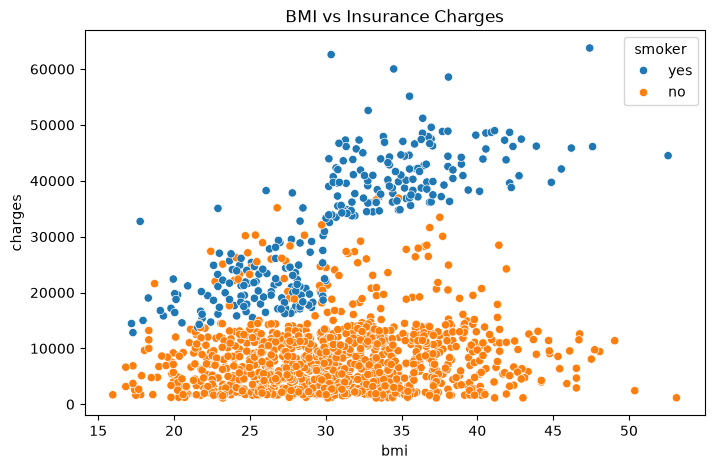

In [18]:
# BMI vs Charges
plt.figure(figsize=(8,5))
sns.scatterplot(x='bmi',y='charges', hue='smoker', data=df)
plt.title("BMI vs Insurance Charges")
plt.show()

### Interpretation
As BMI increases, insurance charges tend to also increase. The effect is noticeable for smokers, who particularly experience significantly higher charges across most BMI levels.

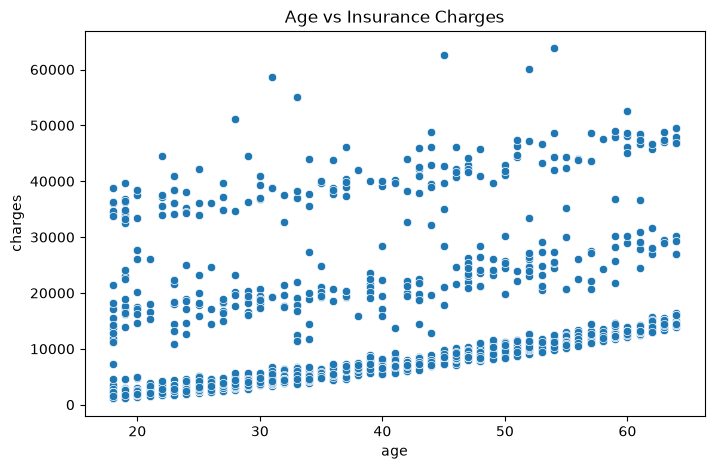

In [19]:
# Age vs Charges
plt.figure(figsize=(8,5))
sns.scatterplot(x='age', y='charges', data=df)
plt.title("Age vs Insurance Charges")
plt.show()

### Interpretation
Older individuals generally experience higher insurance costs. This suggests that age is psitively associated with medical insurance expenses.

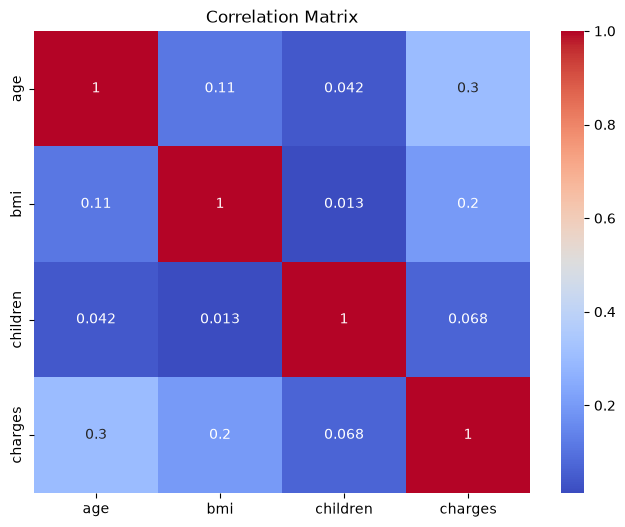

In [21]:
# Correlation heatmap
numeric_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

## EDA Summary
The analysis suggests that smoking has the strongest influence on insurance charges. Age shows a positive relationship with charges. BMI has a moderate positive effect on charges while number of children has a relatively weak relationship with charges. The predictive modelling process will be guided by the above observations.

# Task 4: Data Preprocessing

Numerical predictors are required for machine learning and building the linear regression model. Linear regression uses a mathematical equation to estimate the relatioship between predictors and the outcome. For this reason, categorical predictors must be represented appropriately since the model performs numerical calculations. **sex**, **smoker**, **region** are all categorical variables and must be converted into numerical format before the model can be trained. One-hot encoding will be used to create dummy variables for each category while avoiding issues caused by assigning arbitrary numerical values. This means that the conversion enables the linear regression model to incorporate group membership without incorrectly assuming that category labels have numerical meaning or that the categories are equally spaced.

In [28]:
# Converting categorical variables to dummy variables
df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

#Displaying the first five rows of the processed dataset
df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [29]:
# Checking the structure of the dataset
df.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1337 non-null   int64  
 1   bmi               1337 non-null   float64
 2   children          1337 non-null   int64  
 3   charges           1337 non-null   float64
 4   sex_male          1337 non-null   bool   
 5   smoker_yes        1337 non-null   bool   
 6   region_northwest  1337 non-null   bool   
 7   region_southeast  1337 non-null   bool   
 8   region_southwest  1337 non-null   bool   
dtypes: bool(5), float64(2), int64(2)
memory usage: 58.8 KB


### Preprocessing outcome
The categorical variable have now been successfully converted into binary numerical variables:

- sex is now sex_male
- smoker is now smoker_yes
- region is now region_northwest, region_southeast, region_southwest

The dataset is now ready for feature selection and machine learning model training.

# Task 5: Defining the features and the target variable

Target variable (y): charges
Feature variables (x): all remaining variables in the medical insurance dataset; **sex**, **age**, **bmi**, **number of children**, **region**, **smoker**.

The target variable is the variable the model aims to estimate and it represents the quantity of interests as it becomes the central focus of the analysis. The feature variables contain information that helps explain variation in the target, they are predictors.

Separating the dataset into features and a target variable is a critical step in supervised machine learning. The model analyses patterns in the features variables and learns how these patterns relate to the target variable. Once trained, the model can use this learned relationship to predict insurance charges for previously unseen observations. After defining the features and target variable, the dataset is ready to be split into training and testing subsets for model development and evaluation. 

In [31]:
# Features
X = df.drop('charges', axis=1)

# Target variable
y = df['charges']
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

# Displaying feature names
print("\nFeature Variables:")
print(X.columns.tolist())

Feature Shape: (1337, 8)
Target Shape: (1337,)

Feature Variables:
['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


# Task 6: Splitting the dataset into Training and Testing sets

The dataset is divided into training (80%) and testing (20%) obseravtions. To prevent information from the test set from influencing model development, feature selection is performed using the training data only. The primary purpose of splitting the dataset into training and test sets is to evaluate how a machine learning model generalizes to new and unseen data rather than just memorizing the data it was trained on. It measures real-world performance, prevents overfitting of the model and prevents data leaks.

- Training data is used to teach the model
- Testing data is used to evaluate the model's performance on unseen observations.

An 80:20 split is used.

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42)
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
    

Training Features: (1069, 8)
Testing Features: (268, 8)


The dataset was split into 1069 training set and 268 testing features, this correspond to the 80:20 split. The training set provides sufficient data for the model to learn the underlying relationships. This split supports model learning and performance assessment because the test set also contains enough observations to relaibly evaluate how well the model generalizes to new and unseen data.

# Task 7: Training the Linear Regression Model

A linear regression model is a supervised machine learning algorithm used to predict continuous numerical values. During model training, the model learns optimal coefficients for each feature by analysing the training data. These coefficients indicate the degree to which each predictor influences insurance while holding other variables constant. The trained model can then be used to estimate medical insurance costs for new individuals whose charges are unkwown.


In [33]:
# Creating a Linear Regression Model
model = LinearRegression()

#Training the model using training data
model.fit(X_train, y_train)
print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [34]:
# Displaying model parameters

#Displaying the intercept
print("Intercept:")
print(model.intercept_)

#Display regression coefficients
coefficients = pd.DataFrame({'Feature': X.columns,
                             'Coefficient': model.coef_})
coefficients.sort_values(by='Coefficient', ascending=False)

Intercept:
-11092.652295945933


,Feature,Coefficient
4,smoker_yes,23077.764593
2,children,533.009989
1,bmi,318.701441
0,age,248.210720
3,sex_male,-101.542054
5,region_northwest,-391.761455
7,region_southwest,-659.139752
6,region_southeast,-838.919616


In [35]:
# Calculating the training score
training_score = model.score(X_train, y_train)
print("Training R2 Score:", round(training_score, 4))

Training R2 Score: 0.7299


The linear regression model was successfully trained using the training dataset. The algorithm learned the relationship between age, BMI, sex, number of children, smoking status and region during training, and how these variables collectively  influence medical insurance charges. The intercept represents the baseline prediction of insurance charges when all predictor variables are 0. The coefficients indicate how much the predicted insurance charge changes when a particular feature increases by one unit, while all other variables remain constant. Negative coefficients indicate a decrease in predicted charges whereas positive coefficients suggest a variable increases insurance charges.

# Task 8: Making Predictions 
The trained model is used to make predictions on insurance charges for the test dataset.

In [36]:
# Generate predictions
y_pred = model.predict(X_test)

# Compare actual and predicted values
results = pd.DataFrame({'Actual': y_test,
                        'Predicted': y_pred})
results.head(10)

,Actual,Predicted
900,8688.85885,8143.693884
1064,5708.86700,5737.115683
1256,11436.73815,14369.314876
298,38746.35510,31745.513636
237,4463.20510,8962.386657
481,9304.70190,13149.722353
240,38511.62830,30446.760679
277,2150.46900,1453.288813
415,7345.72660,10633.018402
707,10264.44210,11318.943794


The comparison between actual and predicteed charges demonstrates that the linear regression model produces substantial errors. The model shows poor generalization on the test set especially for observations with low actual charges. An additional model may be required to improve predictive accuracy.

# Task 9: Evaluating the model performance
The following metrics are used for the model evaluation which in turn measures how accurately the model predicts insurance charges.

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R-squared (R2)


In [38]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R-squared Score:", r2)

Mean Absolute Error: 4177.04556103632
Mean Squared Error: 35478020.67523562
Root Mean Squared Error: 5956.342894363589
R-squared Score: 0.8069287081198011


- A lower MAE indicates smaller prediction errors
- A lower RMSE indicates better predictive accuracy
- The higher R2 value suggests a stronger predictive model, it indicates how much variation in insurance charges is explained by the model.

# Task 10: Reflection

After exploring and analysing the medical insurance dataset, the EDA showed that smoking status has the strongest influence on medical insurance charges. BMI and age also contribute significantly to higher costs, while the number of children has a smaller effect. Smoking increases the risk of numerous health conditions such as lung disease, cancer and heart disease. As a results, smokers often require more medical care and treatment which leads to higher insurance claims and increased insurance charges.

## Improvements that can be made to the model to enhance its performance
- Including more health-related variables
- Using advanced machine learning models such as Random Forest
- Investigating outliers and their impact on predictions
- Applying cross-validation to improve model reliability

In conclurion, the linear regression model provides a useful baseline for predicting medical insurance costs and identifying important cost drivers.  